In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize

In [2]:
from tqdm.auto import tqdm

In [3]:
import mctpy as mct

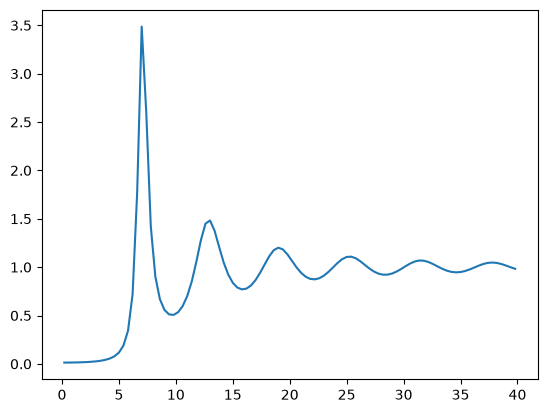

In [4]:
Sq = mct.structurefactors.hssPY(0.51593)
qgrid = np.linspace(0.2,39.8,100)
sq,cq = Sq.Sq(qgrid)
plt.plot(qgrid,sq)
plt.show()

In [5]:
model = mct.simple_liquid_model(Sq,qgrid)

In [6]:
nep = mct.nonergodicity_parameter (model = model)
nep.solve()

In [7]:
cs = mct.structurefactors.hssPYtagged(phi=Sq.phi,delta=1)
model_s = mct.tagged_particle_model (model, Sq=cs, D0s=1)
nep_s = mct.nonergodicity_parameter (model = model_s)
nep_s.solve()

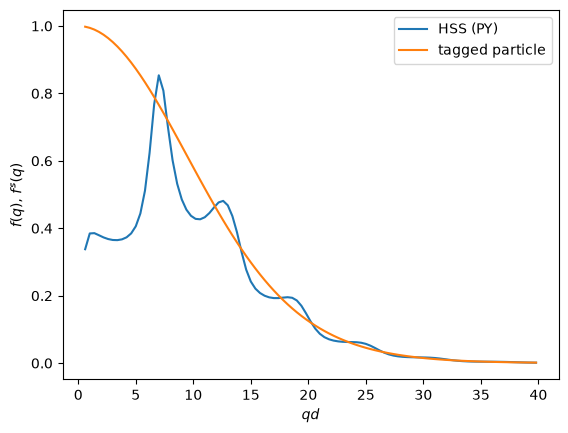

In [8]:
plt.plot(nep.model.q[1:], nep.f[1:], label='HSS (PY)')
plt.plot(nep_s.model.q[1:], nep_s.f[1:], label='tagged particle')
plt.xlabel(r'$qd$')
plt.ylabel(r'$f(q)$, $f^s(q)$')
plt.legend()
plt.show()

In [9]:
class evsearch_hss:
    def __init__ (self):
        self.model = None
    def calc_ev (self, phi):
        Sq = mct.structurefactors.hssPY(phi)
        if self.model is None:
            self.model = mct.simple_liquid_model (Sq, qgrid)
        else:
            self.model.set (Sq=Sq)
        nep = mct.nonergodicity_parameter (model = self.model)
        nep.solve()
        ev = mct.eigenvalue (nep)
        ev.solve()
        return ev
phis, evs = mct.util.evscan (0.51, 0.52, evsearch_hss().calc_ev, eps=1e-8)

In [10]:
# The following should print phi_c = 0.51591214(1), lambda = 0.735, ev = 0.999844
p=np.argmax([ev.eval for ev in evs])
print("phi_c = {:.8f}(1), lambda = {:.3f}, ev = {:.6f}".format(phis[p],evs[p].lam,evs[p].eval))

phi_c = 0.51591214(1), lambda = 0.735, ev = 0.999844


In [11]:
hss_c = evs[p]
phi_c = phis[p]

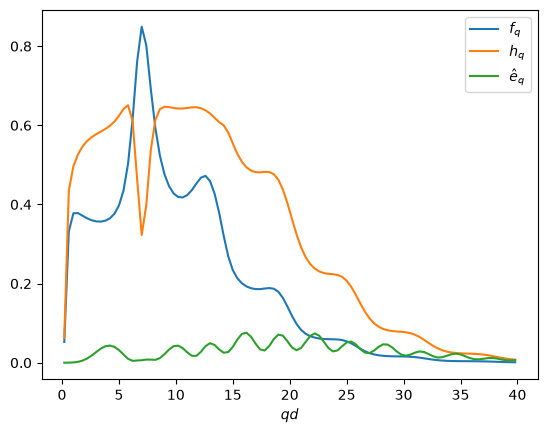

In [12]:
plt.plot(qgrid,hss_c.nep.f,label=r'$f_q$')
plt.plot(qgrid,hss_c.e*(1-hss_c.nep.f)**2,label=r'$h_q$')
plt.plot(qgrid,hss_c.ehat,label=r'$\hat e_q$')
plt.legend()
plt.xlabel(r'$qd$')
plt.show()

In [13]:
m1 = mct.simple_liquid_model(mct.structurefactors.hssPY(0.),qgrid)
phirange = np.linspace(0.46,0.58,101)
sigrange = np.zeros_like(phirange)
for i, phi in enumerate(phirange):
    m1.set (Sq=mct.structurefactors.hssPY(phi))
    sigrange[i] = hss_c.sigma (m1)

In [14]:
#filter = np.abs(sigrange) < 0.005
#popt, pcov = scipy.optimize.curve_fit (lambda eps, C: C*eps, (phirange[filter]-phi_c)/phi_c, sigrange[filter])
#C = popt[0]
epsrange = (phirange-phi_c)/phi_c
C = np.interp(0.,epsrange,sigrange/epsrange)

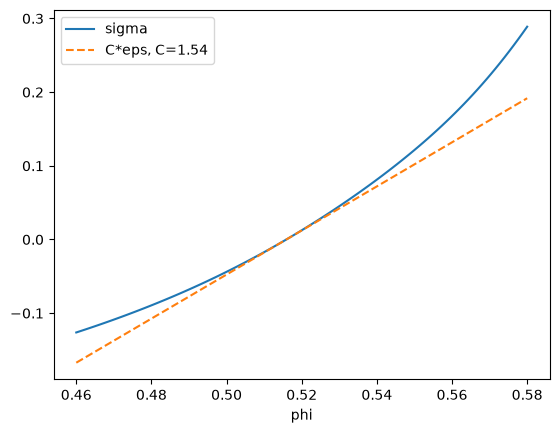

In [15]:
plt.plot(phirange, sigrange, label='sigma')
plt.plot(phirange, C*(phirange-phi_c)/phi_c, label=f'C*eps, C={C:.2f}', linestyle='dashed')
plt.legend()
plt.xlabel('phi')
plt.show()

In [16]:
nlist = [-3,-6,-9,-12,0,9,6,3]
philist = mct.CorrelatorStack()
for n in nlist:
    phi = phi_c*(1 + np.sign(n)*10**(-np.abs(n)/3.))
    Sq = mct.structurefactors.hssPY(phi)
    model = mct.simple_liquid_model(Sq,qgrid)
    philist.append(mct.correlator (model = model, store=True))

In [17]:
philist.solve_all(progress_bar=tqdm)

  0%|          | 0/60 [00:00<?, ?it/s]

True

In [18]:
#qvals = [3.4,7.4,12.2]
qvals = [7.0, 10.6]
qis = np.array([np.nonzero(np.isclose(qgrid,qval)) for qval in qvals],dtype=int).reshape(-1)

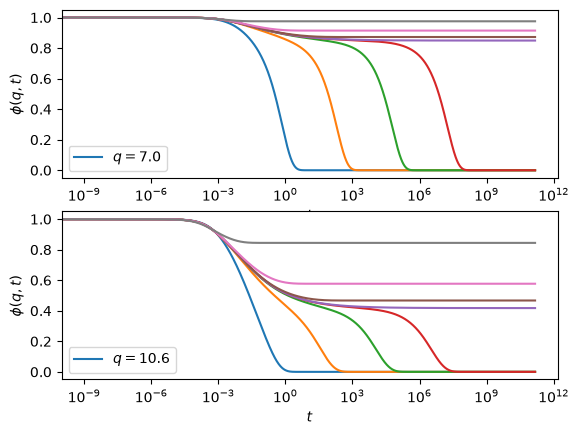

In [19]:
fig, ax = plt.subplots(nrows=2, ncols=1)
for i, qi in enumerate(qis):
    ltxt = r'$q = {:.1f}$'.format(qgrid[qi])
    for phi in philist:
        ax[i].plot(phi.t, phi.phi[:,qi], label=ltxt)
        ltxt = ''
    ax[i].set_xscale('log')
    ax[i].set_xlabel(r'$t$')
    ax[i].set_ylabel(r'$\phi(q,t)$')
    ax[i].legend()
plt.show()

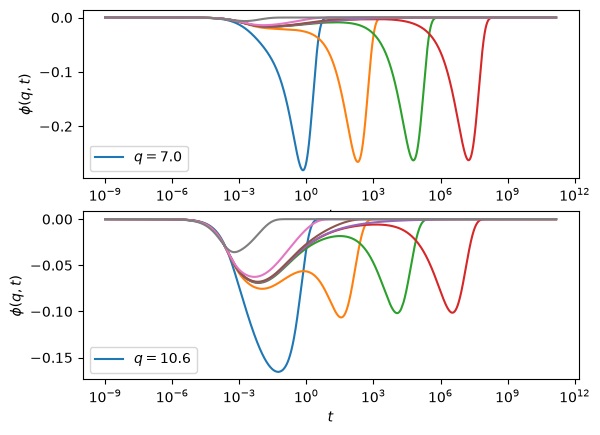

In [20]:
fig, ax = plt.subplots(nrows=2, ncols=1)
for i, qi in enumerate(qis):
    ltxt = r'$q = {:.1f}$'.format(qgrid[qi])
    for phi in philist:
        ax[i].plot(phi.t[1:], np.gradient(phi.phi[1:,qi],np.log(phi.t[1:])), label=ltxt)
        ltxt = ''
    ax[i].set_xscale('log')
    ax[i].set_xlabel(r'$t$')
    ax[i].set_ylabel(r'$\phi(q,t)$')
    ax[i].legend()
plt.show()

In [21]:
wrange = 160*10**np.linspace(-12,2,100)
chidlist = []
chiddlist = []
for phi in philist:
    # for Q qvectors out of M, T time points and W frequency points
    # f has shape (T,M)
    f = phi.phi - phi.phi[-1] # subtract finite last value to omit delta contribution
    t_, w_ = np.meshgrid(phi.t, wrange)
    f_, _ = np.meshgrid(f[:,qis].T, wrange)
    # f_ now has shape (W, Q*T) since meshgrid flattens
    # reshape back to (W,Q,T), transpose to (Q,W,T)
    f_ = np.transpose(f_.reshape(wrange.shape[0],qis.shape[0],-1),axes=(1,0,2))
    # works because t_ has shape (W,T)
    chidlist.append(mct.util.filon_sin_transform(f_,t_,w_))
    chiddlist.append(mct.util.filon_cos_transform(f_,t_,w_))

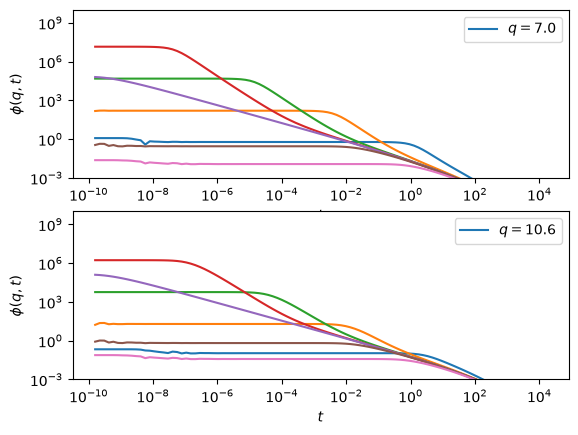

In [22]:
fig, ax = plt.subplots(nrows=2, ncols=1)
for i, qi in enumerate(qis):
    ltxt = r'$q = {:.1f}$'.format(qgrid[qi])
    for chi in chiddlist:
        ax[i].plot(wrange, chi[i], label=ltxt)
        ltxt = ''
    ax[i].set_xscale('log')
    ax[i].set_yscale('log')
    ax[i].set_ylim(0.001,1e10)
    ax[i].set_xlabel(r'$t$')
    ax[i].set_ylabel(r'$\phi(q,t)$')
    ax[i].legend()
plt.show()

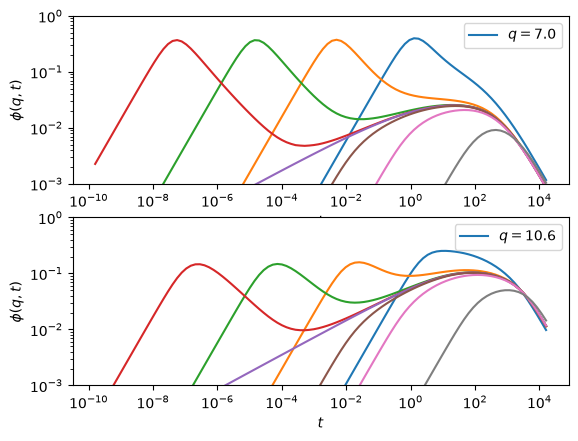

In [23]:
fig, ax = plt.subplots(nrows=2, ncols=1)
for i, qi in enumerate(qis):
    ltxt = r'$q = {:.1f}$'.format(qgrid[qi])
    for chi in chiddlist:
        ax[i].plot(wrange, wrange*chi[i], label=ltxt)
        ltxt = ''
    ax[i].set_xscale('log')
    ax[i].set_yscale('log')
    ax[i].set_ylim(0.001,1)
    ax[i].set_xlabel(r'$t$')
    ax[i].set_ylabel(r'$\phi(q,t)$')
    ax[i].legend()
plt.show()

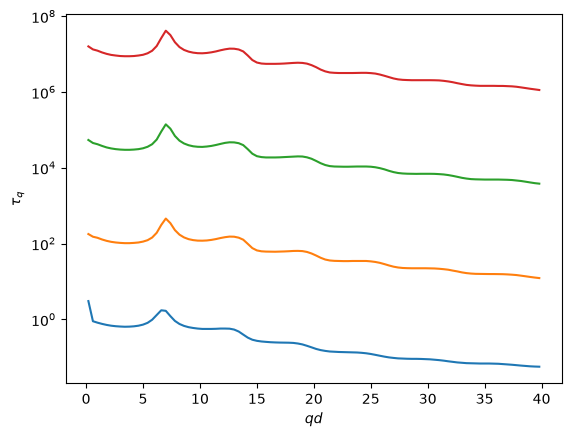

In [24]:
for phi in philist[:4]:
    tau_indices = phi.phi.shape[0] - np.sum(phi.phi/nep.f<=0.1,axis=0)
    tau_indices[tau_indices>=phi.phi.shape[0]] = -1
    tau = phi.t[tau_indices]
    plt.plot(model.q,tau)
plt.yscale('log')
plt.xlabel(r'$qd$')
plt.ylabel(r'$\tau_q$')
plt.show()

In [25]:
cs = mct.structurefactors.hssPYtagged(phi=philist[2].model.Sq.phi,delta=1)
model_s = mct.tagged_particle_model (philist[2].model, Sq=cs, D0s=1)
phi_s = mct.correlator (model = model_s, base=philist[2], store = True)
correlators = mct.CorrelatorStack([philist[2],phi_s])

In [26]:
model_s0 = mct.tagged_particle_q0 (model_s)
msd = mct.mean_squared_displacement (model = model_s0, base=phi_s, store=True)
correlators.append(msd)

In [27]:
model_ngp = mct.tagged_particle_ngp (model_s0)
ngp = mct.non_gaussian_parameter (model = model_ngp, base=msd, store=True)
correlators.append(ngp)

In [28]:
pbar = tqdm(total=phi.blocks+1)
correlators.solve_all(callback=lambda d,bs2,bs,c: pbar.update(1))
pbar.close()

  0%|          | 0/61 [00:00<?, ?it/s]

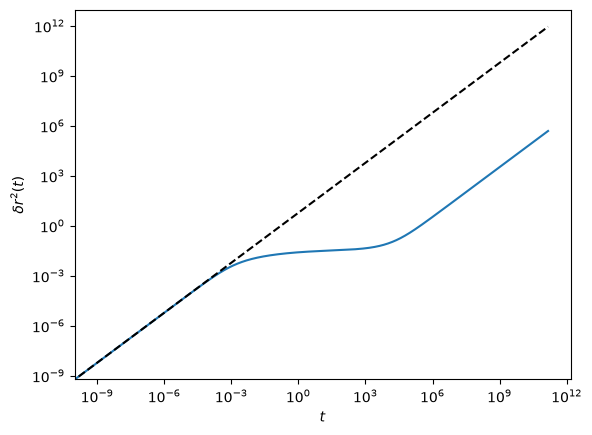

In [29]:
plt.plot(msd.t, msd.phi[:,0])
plt.plot(msd.t, 6*msd.t, color='black', linestyle='dashed')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$t$')
plt.ylabel(r'$\delta r^2(t)$')
plt.show()

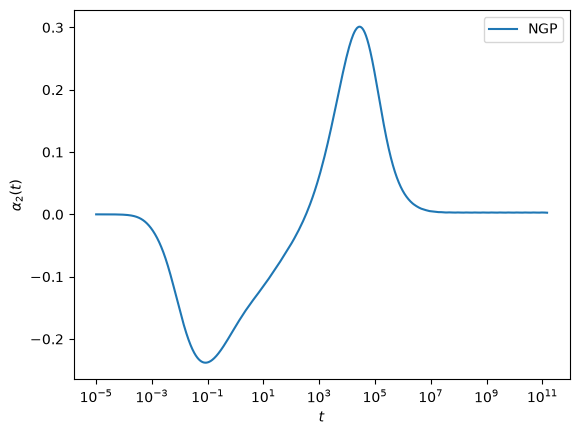

In [30]:
plt.plot(ngp.t[ngp.t>1e-5], (ngp.phi[:,0][ngp.t>1e-5]/ngp.phi[:,1][ngp.t>1e-5]**2 - 1), label='NGP')
plt.xscale('log')
plt.legend()
plt.xlabel(r'$t$')
plt.ylabel(r'$\alpha_2(t)$')
plt.show()

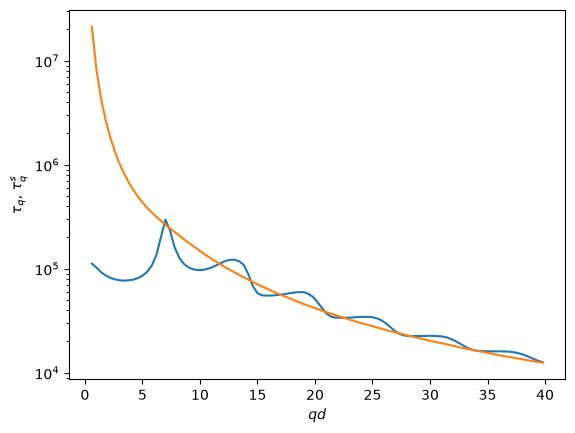

In [31]:
for corr,f in [(philist[2],nep.f),(phi_s,nep_s.f)]:
    tau_indices = corr.phi.shape[0] - np.sum(corr.phi/f<=0.01,axis=0)
    tau_indices[tau_indices>=corr.phi.shape[0]] = -1
    tau = corr.t[tau_indices]
    plt.plot(model.q[1:],tau[1:])
plt.yscale('log')
plt.xlabel(r'$qd$')
plt.ylabel(r'$\tau_q$, $\tau^s_q$')
plt.show()

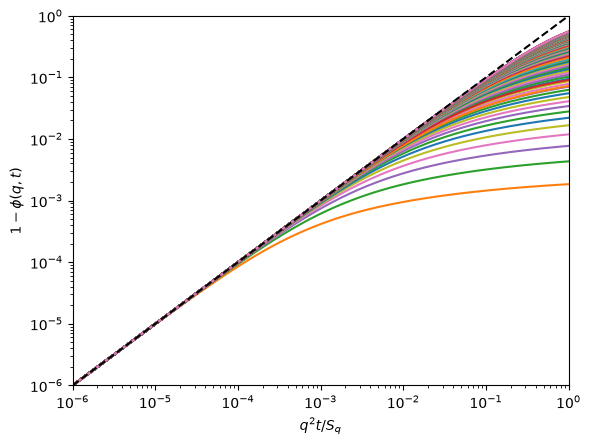

In [32]:
for phi in [philist[2]]:
    for qi, q in enumerate(qgrid):
        if qi > 2:
            plt.plot(phi.t*q*q/sq[qi], 1-phi.phi[:,qi], label=r'$q = {:.1f}$'.format(qgrid[qi]))
        plt.plot(phi_s.t*q*q, 1-phi_s.phi[:,qi], label=r'$q = {:.1f}$'.format(qgrid[qi]))
plt.plot(phi_s.t,phi_s.t,color='black',linestyle='dashed')
plt.xscale('log')
plt.xlabel(r'$q^2t/S_q$')
plt.ylabel(r'$1-\phi(q,t)$')
plt.xlim(1e-6,1)
plt.yscale('log')
plt.ylim(1e-6,1)
#plt.legend()
plt.show()